# Lista de Exercícios 6 — Árvores e Arborescências (Parte 2): Kruskal e Prim

**Instituição:** Instituto Federal Goiano — Campus Iporá (Bacharelado em Ciência da Computação)  
**Disciplina:** Teoria dos Grafos • 3º Período — 2026/2  
**Professor:** Prof. Newarney T. Costa  
**Integrantes:** Messias Junio da Silva Mendes (`Messias-Mendes-Oficial`) | Bruno Alves Mendonça De Abreu Filho  

Este notebook foi estruturado para rodar integralmente no **Google Colab** (suportando tanto **Python 3** quanto compilação em **C via `gcc`**) e reúne a resolução completa das **Questões 1, 2 e 3** da Lista de Exercícios 6.

## Questão 1 — Algoritmos de Kruskal e Prim: Conceitos, Complexidade e Estruturas

* **(a) Estratégia de escolha das arestas:**
  * **Kruskal:** Ordena todas as arestas do grafo em ordem crescente de peso e, a cada passo, escolhe a aresta de menor peso global que **não forme ciclo** com as arestas já selecionadas (mantendo uma floresta de componentes que vão se unindo).
  * **Prim:** Parte de um vértice raiz arbitrário e mantém uma **única árvore conexa** $T$, escolhendo a cada passo a aresta de menor peso no corte $(V(T), V \setminus V(T))$ — isto é, que conecta um vértice já incluído na árvore a um vértice ainda fora dela.
* **(b) Funcionamento em grafos desconexos:**
  * **Não produzem uma única árvore**, pois um grafo desconexo não possui árvore geradora. O algoritmo de **Kruskal** funciona naturalmente sem modificação e produz uma **floresta geradora mínima** (uma AGM para cada componente conexa). Já o algoritmo de **Prim**, ao iniciar em um único vértice, explora apenas a componente conexa daquele vértice (precisando ser reiniciado nos vértices ainda não visitados para gerar a floresta geradora mínima completa).
* **(c) Complexidade assintótica e quando cada um é mais vantajoso:**
  * **Kruskal:** $O(E \log E)$ ou $O(E \log V)$ (dominado pela ordenação das $E$ arestas). É mais vantajoso em **grafos esparsos** ($E \approx O(V)$), onde ordenar poucas arestas é muito rápido e simples.
  * **Prim:**
    * Usando **lista de adjacência + fila de prioridade (Min-Heap binário):** $O(E \log V)$ (ou $O(E + V \log V)$ com Heap de Fibonacci), muito eficiente para grafos esparsos.
    * Usando **matriz de adjacência + vetor de custos mínimos (`key[]`):** $O(V^2)$, que é **mais vantajoso em grafos densos** ($E \approx V^2$), pois evita o fator logarítmico $\log V$ do heap e da ordenação de $O(V^2)$ arestas.
* **(d) Estruturas de dados fundamentais:**
  * **Kruskal:** **Union-Find** (*Disjoint Set Union — DSU*), para verificar em tempo quase constante $O(\alpha(V))$ se dois vértices pertencem à mesma componente conexa (evitando ciclos) e unir conjuntos.
  * **Prim:** **Fila de Prioridade (Min-Heap)** (ou vetor de distâncias `key[]` no caso denso), para selecionar rapidamente a aresta mais leve que atravessa o corte entre os vértices na árvore e os vértices fora dela.

## Questão 2 — Aplicação de Kruskal e Prim (Grafo $A, B, C, D$)

Considere o grafo ponderado com vértices $V = \{A, B, C, D\}$ e arestas:
$$(A, B) = 1, \quad (B, C) = 2, \quad (A, C) = 3, \quad (B, D) = 4, \quad (C, D) = 5$$

### (a) Aplicando Kruskal
Ordenando as arestas em ordem crescente de peso:

| Ordem | Aresta | Peso | Decisão | Justificativa |
| :---: | :---: | :---: | :---: | :--- |
| 1º | $A\text{--}B$ | 1 | **Aceita** | Une componentes $\{A\}$ e $\{B\}$ (sem ciclo) |
| 2º | $B\text{--}C$ | 2 | **Aceita** | Une $\{A, B\}$ e $\{C\}$ (sem ciclo) |
| 3º | $A\text{--}C$ | 3 | **Rejeitada** | Formaria o ciclo $A\text{--}B\text{--}C\text{--}A$ |
| 4º | $B\text{--}D$ | 4 | **Aceita** | Une $\{A, B, C\}$ e $\{D\}$ ($|V|-1 = 3$ arestas atingidas) |
| 5º | $C\text{--}D$ | 5 | **Rejeitada** | Formaria o ciclo $B\text{--}C\text{--}D\text{--}B$ |

* **AGM obtida (Kruskal):** $\{(A, B), (B, C), (B, D)\}$ — **Peso total:** $1 + 2 + 4 = \mathbf{7}$.

### (b) Aplicando Prim a partir do vértice $A$

| Passo | Vértices na Árvore ($S$) | Arestas no Corte $(S, V \setminus S)$ | Aresta Escolhida |
| :---: | :---: | :--- | :---: |
| Início | $\{A\}$ | $(A,B):1,\; (A,C):3$ | — |
| 1 | $\{A, B\}$ | $(B,C):2,\; (A,C):3,\; (B,D):4$ | **$A\text{--}B$ (peso 1)** |
| 2 | $\{A, B, C\}$ | $(B,D):4,\; (C,D):5$ *(aresta $A\text{--}C$ é interna a $S$)* | **$B\text{--}C$ (peso 2)** |
| 3 | $\{A, B, C, D\}$ | Todos os vértices incluídos | **$B\text{--}D$ (peso 4)** |

* **AGM obtida (Prim):** $\{(A, B), (B, C), (B, D)\}$ — **Peso total:** $1 + 2 + 4 = \mathbf{7}$.

### (c) Comparação
* **Neste grafo as árvores obtidas são iguais?** **Sim**, ambos selecionaram exatamente as arestas $A\text{--}B (1)$, $B\text{--}C (2)$ e $B\text{--}D (4)$, com peso total $7$ (como todos os pesos das arestas são distintos, a Árvore Geradora Mínima é única).
* **Isso acontece sempre?** **Não necessariamente.** Quando o grafo possui múltiplas arestas com o **mesmo peso** em um mesmo corte ou ciclo, Kruskal e Prim (dependendo do critério de desempate e do vértice inicial) podem produzir **árvores geradoras mínimas estruturalmente diferentes**, mas **ambas terão sempre o mesmo peso total mínimo ótimo**.

=== Questão 2(a): Execução do Algoritmo de Kruskal ===
  Aresta A-B (peso 1): ACEITA
  Aresta B-C (peso 2): ACEITA
  Aresta A-C (peso 3): REJEITADA (forma ciclo)
  Aresta B-D (peso 4): ACEITA
  Aresta C-D (peso 5): REJEITADA (forma ciclo)
  -> AGM Kruskal: [('A', 'B', 1), ('B', 'C', 2), ('B', 'D', 4)] | Peso Total = 7

=== Questão 2(b): Execução do Algoritmo de Prim (Início em A) ===
  Passo 1: Vértices=['A', 'B'] | Aresta escolhida: A-B (peso 1)
  Passo 2: Vértices=['A', 'B', 'C'] | Aresta escolhida: B-C (peso 2)
  Passo 3: Vértices=['A', 'B', 'C', 'D'] | Aresta escolhida: B-D (peso 4)
  -> AGM Prim:    [('A', 'B', 1), ('B', 'C', 2), ('B', 'D', 4)] | Peso Total = 7


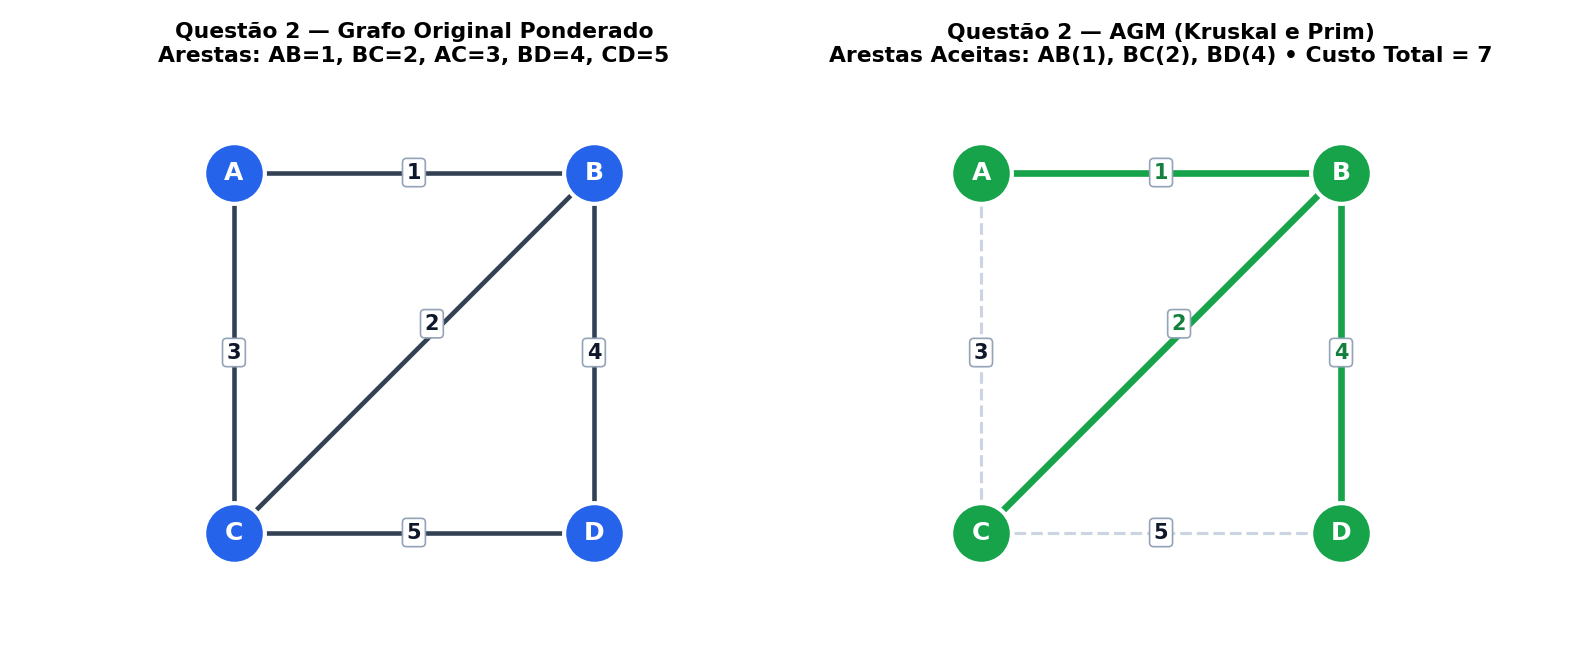

In [1]:
# Verificação Computacional da Questão 2 (Kruskal e Prim em Python)
vertices_q2 = ['A', 'B', 'C', 'D']
arestas_q2 = [('A', 'B', 1), ('B', 'C', 2), ('A', 'C', 3), ('B', 'D', 4), ('C', 'D', 5)]

# 1. Algoritmo de Kruskal com Union-Find
pai = {v: v for v in vertices_q2}
def find(v):
    if pai[v] != v:
        pai[v] = find(pai[v])
    return pai[v]

agm_kruskal = []
peso_kruskal = 0
print("=== Questão 2(a): Execução do Algoritmo de Kruskal ===")
for u, v, w in sorted(arestas_q2, key=lambda x: x[2]):
    ru, rv = find(u), find(v)
    if ru != rv:
        pai[ru] = rv
        agm_kruskal.append((u, v, w))
        peso_kruskal += w
        print(f"  Aresta {u}-{v} (peso {w}): ACEITA")
    else:
        print(f"  Aresta {u}-{v} (peso {w}): REJEITADA (forma ciclo)")
print(f"  -> AGM Kruskal: {agm_kruskal} | Peso Total = {peso_kruskal}\n")

# 2. Algoritmo de Prim iniciando em 'A'
visitados = {'A'}
agm_prim = []
peso_prim = 0
print("=== Questão 2(b): Execução do Algoritmo de Prim (Início em A) ===")
passo = 1
while len(visitados) < len(vertices_q2):
    candidatas = [
        (u, v, w) for (u, v, w) in arestas_q2
        if (u in visitados and v not in visitados) or (v in visitados and u not in visitados)
    ]
    u_esc, v_esc, w_esc = min(candidatas, key=lambda x: x[2])
    novo = v_esc if u_esc in visitados else u_esc
    visitados.add(novo)
    agm_prim.append((u_esc, v_esc, w_esc))
    peso_prim += w_esc
    print(f"  Passo {passo}: Vértices={sorted(visitados)} | Aresta escolhida: {u_esc}-{v_esc} (peso {w_esc})")
    passo += 1
print(f"  -> AGM Prim:    {agm_prim} | Peso Total = {peso_prim}")

## Questão 3 — Prim · Implementação

### 3.1 Leia e Explique (Funcionamento Passo a Passo e Análise de Complexidade)

#### 1. O que o código em C faz e como funciona passo a passo:
* **Linhas 7–15 (Entrada de Dados):** Lê o número de vértices `n` e preenche a matriz de adjacência de custos `cost[n][n]`, onde `cost[i][j]` armazena o peso da aresta entre `i` e `j` (ou `0` quando não há aresta no modelo de entrada desse código).
* **Linhas 17–19 (Inicialização da Árvore):** Declara o vetor `selected[n]` que indica se cada vértice já pertence à Árvore Geradora Mínima (`1`) ou ainda não (`0`). Inicializa todos com `0` e inclui o vértice `0` como raiz inicial da árvore (`selected[0] = 1`).
* **Linhas 21–22 (Controle do Laço Principal):** Inicializa o contador de arestas da AGM `edges = 0` e o custo acumulado `mincost = 0`. Como toda árvore geradora de $n$ vértices possui exatamente $n - 1$ arestas, o laço `while (edges < n - 1)` executa exatamente **$n - 1$ iterações**.
* **Linhas 23–35 (Busca Exaustiva da Aresta Mínima no Corte):** Em cada iteração do `while`, inicializa `min = INF` e `x = 0, y = 0`.
  * O laço `for (int i = 0; i < n; i++)` percorre todos os vértices e filtra apenas aqueles que **já estão na árvore** (`if (selected[i])`).
  * Para cada vértice `i` na árvore, o laço interno `for (int j = 0; j < n; j++)` percorre todos os vértices `j` que **ainda não estão na árvore** (`!selected[j]`) e possuem ligação com `i` (`cost[i][j] != 0`).
  * Se `cost[i][j] < min`, atualiza o menor peso encontrado (`min = cost[i][j]`) e guarda os extremos da aresta candidata (`x = i; y = j;`).
* **Linhas 36–40 (Inclusão da Aresta na AGM):** Imprime a aresta escolhida `(x, y)` e seu custo `min`, soma `min` ao custo total (`mincost += min`), marca o novo vértice `y` como pertencente à árvore (`selected[y] = 1`) e incrementa o contador de arestas (`edges++`).
* **Linhas 41–42:** Ao sair do `while` (com $n-1$ arestas inseridas), exibe o custo total mínimo da AGM (`mincost`).

#### 2. Análise de Complexidade dos Três Laços Aninhados (`while`, `for i`, `for j`):
* **Laço externo `while (edges < n - 1)`:** executa exatamente $n - 1$ vezes $\Rightarrow O(n)$.
* **Laço intermediário `for (int i = 0; i < n; i++)`:** executa $n$ vezes para cada passo do `while`. Na $k$-ésima iteração do `while` ($k = 1, 2, \dots, n-1$), existem exatamente $k$ vértices com `selected[i] == 1`.
* **Laço interno `for (int j = 0; j < n; j++)`:** executa $n$ vezes para cada um dos $k$ vértices selecionados.
* **Total de comparações no laço mais interno:**
  $$T(n) = \sum_{k=1}^{n-1} (k \cdot n) = n \sum_{k=1}^{n-1} k = n \cdot \frac{(n-1)n}{2} = \frac{n^3 - n^2}{2} = \mathbf{O(n^3)} \text{ (ou } \mathbf{O(V^3)}\text{)}$$

#### 3. É a versão eficiente da Questão 1 ou a versão mais simples/ingênua? Como reduzir a complexidade?
* **Resposta:** Trata-se da **versão mais simples/ingênua ($O(V^3)$)**, e **não** das versões eficientes discutidas na Questão 1 ($O(V^2)$ ou $O(E \log V)$).
* **Justificativa:** Ela é ingênua porque **não guarda memória das menores distâncias já descobertas** entre a árvore e os vértices externos: a cada nova iteração do `while`, ela reexamina do zero todas as células `cost[i][j]` entre todos os vértices já visitados `i` e todos os não visitados `j` ($O(V^2)$ por iteração $\times (V-1)$ iterações $= O(V^3)$).
* **O que mudaria para reduzir a complexidade?**
  1. **Para reduzir de $O(V^3)$ para $O(V^2)$ (mantendo a matriz de adjacência):**
     Criamos dois vetores auxiliares de tamanho $n$: `key[j]` (que armazena o menor peso de aresta conhecido conectando o vértice não visitado `j` a algum vértice já na árvore) e `parent[j]` (qual vértice da árvore oferece essa conexão mínima). Assim, dentro do `while (edges < n - 1)`, substituímos os **dois laços `for` aninhados** por **dois laços `for` separados (sequenciais)**:
     * Um primeiro `for` simples de $O(n)$ apenas para escolher o vértice `y` não selecionado com o menor `key[y]`;
     * Um segundo `for` simples de $O(n)$ (após adicionar `y` à árvore) que olha **apenas a linha `cost[y][j]`** do vértice recém-adicionado `y` para atualizar `if (cost[y][j] < key[j]) { key[j] = cost[y][j]; parent[j] = y; }`.
     * Com isso, cada iteração do `while` passa a custar $O(n) + O(n) = O(n)$, reduzindo o tempo total para $(n-1) \cdot O(n) = \mathbf{O(n^2)} = \mathbf{O(V^2)}$.
  2. **Para reduzir para $O(E \log V)$ (em grafos esparsos):**
     Trocar a matriz de custos `cost[n][n]` por **listas de adjacência** e armazenar os valores de `key[]` em uma **Fila de Prioridade (Min-Heap binário)**.

---
### 3.2 Complete (`// TRECHO FALTANTE`) e Análise do Comportamento

#### 1. Linha que completa o código (Linha 78):
```c
selected[y] = 1;
```

#### 2. O que aconteceria se essa linha fosse omitida — o programa trava, ou termina e dá uma resposta errada? Por quê?
* **Resposta Direta:** O programa **NÃO trava** (não entra em loop infinito); ele **termina normalmente após $n - 1$ iterações, mas produz uma resposta completamente errada!**
* **Explicação detalhada do porquê:**
  1. **Por que ele NÃO trava?** A condição de parada do laço é `while (edges < n - 1)`. Como a instrução `edges++;` (linha 79) continua presente no final do bloco `while`, a variável `edges` é incrementada normalmente a cada passo ($0 \to 1 \to 2 \to \dots \to n-1$). Logo, o laço executa exatamente $n - 1$ vezes e o programa encerra.
  2. **Por que ele dá uma resposta errada?** Sem a linha `selected[y] = 1;`, o vértice `y` recém-escolhido **nunca é marcado como visitado**. Assim, o vetor `selected[]` permanece congelado em seu estado inicial durante toda a execução: apenas `selected[0] == 1` e todos os demais vértices continuam com `selected[j] == 0`.
  3. **Consequência prática:** Em todas as $n - 1$ iterações do `while`, o laço `for i` só entrará em `i = 0` e escolherá **repetidamente a exata mesma aresta `(0, y)` de menor peso que sai do vértice `0`**! Ao final, o programa imprimirá $n - 1$ cópias idênticas dessa única aresta e retornará o falso custo mínimo igual a $(n - 1) \times \min_{j} \text{cost}[0][j]$.

In [2]:
# Demonstração Prática da Questão 3.2: Comparando COM e SEM a linha `selected[y] = 1`
INF = 999999
N = 5
cost_demo = [
    [0, 2, INF, 6, INF],
    [2, 0, 3, 8, 5],
    [INF, 3, 0, INF, 7],
    [6, 8, INF, 0, 9],
    [INF, 5, 7, 9, 0]
]

def simular_prim_q32(omitir_selected=False):
    selected = [0] * N
    selected[0] = 1
    edges = 0
    mincost = 0
    titulo = "OMITINDO `selected[y] = 1;` (BUG)" if omitir_selected else "COM `selected[y] = 1;` (CORRETO)"
    print(f"=== Simulação {titulo} ===")
    while edges < N - 1:
        min_val = INF
        x, y = 0, 0
        for i in range(N):
            if selected[i]:
                for j in range(N):
                    if not selected[j] and cost_demo[i][j]:
                        if min_val > cost_demo[i][j]:
                            min_val = cost_demo[i][j]
                            x, y = i, j
        print(f"  Aresta ({x}, {y}) incluida de custo {min_val}")
        mincost += min_val
        if not omitir_selected:
            selected[y] = 1  # <-- LINHA FALTANTE
        edges += 1
    print(f"  Custo minimo = {mincost}\n")

simular_prim_q32(omitir_selected=True)
simular_prim_q32(omitir_selected=False)

=== Simulação OMITINDO `selected[y] = 1;` (BUG) ===
  Aresta (0, 1) incluida de custo 2
  Aresta (0, 1) incluida de custo 2
  Aresta (0, 1) incluida de custo 2
  Aresta (0, 1) incluida de custo 2
  Custo minimo = 8

=== Simulação COM `selected[y] = 1;` (CORRETO) ===
  Aresta (0, 1) incluida de custo 2
  Aresta (1, 2) incluida de custo 3
  Aresta (1, 4) incluida de custo 5
  Aresta (0, 3) incluida de custo 6
  Custo minimo = 16



---
### 3.3 Implemente — Interligação das 5 Fábricas com Cabos de Fibra Óptica

Abaixo estão as implementações completas tanto em **Python (Google Colab)** quanto em **C (compilado com `gcc` diretamente no Colab)** para o problema das 5 fábricas, gerando exatamente a saída esperada.

Aresta (0, 1) incluida de custo 2
Aresta (1, 2) incluida de custo 3
Aresta (1, 4) incluida de custo 5
Aresta (0, 3) incluida de custo 6
Custo minimo = 16


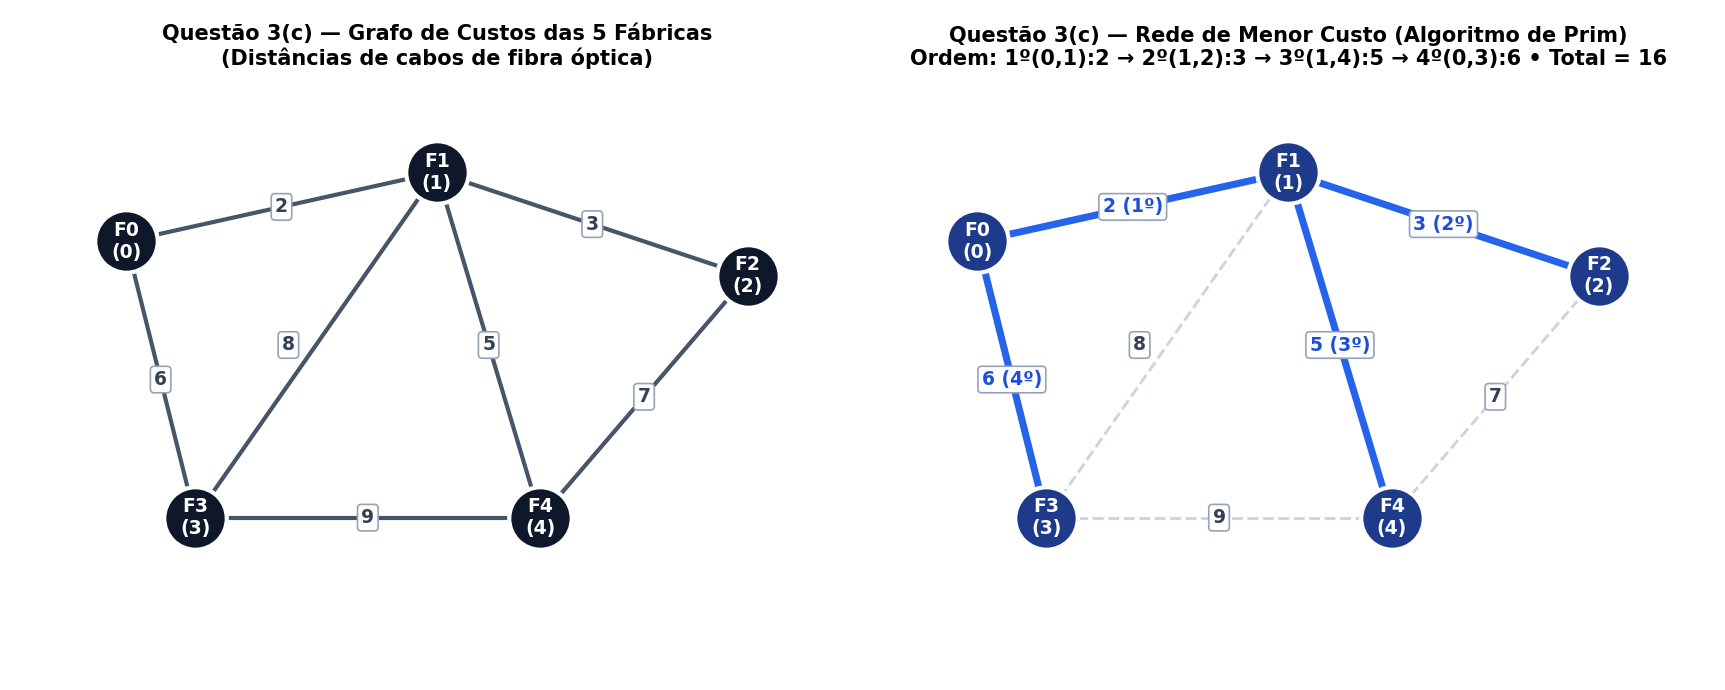

In [3]:
# Questão 3.3 — Implementação Completa em Python (Google Colab)
INF = float('inf')
N = 5
cost = [
    [0, 2, INF, 6, INF],
    [2, 0, 3, 8, 5],
    [INF, 3, 0, INF, 7],
    [6, 8, INF, 0, 9],
    [INF, 5, 7, 9, 0],
]
selected = [False] * N
selected[0] = True

edges, mincost = 0, 0
while edges < N - 1:
    # Encontrar a aresta (x, y) de menor custo ligando um vértice selecionado a um não selecionado
    min_val = INF
    x, y = 0, 0
    for i in range(N):
        if selected[i]:
            for j in range(N):
                if not selected[j] and cost[i][j] > 0:
                    if min_val > cost[i][j]:
                        min_val = cost[i][j]
                        x, y = i, j

    # Imprimir a aresta escolhida, somar ao mincost, marcar y como selecionado e incrementar edges
    print(f"Aresta ({x}, {y}) incluida de custo {min_val}")
    mincost += min_val
    selected[y] = True
    edges += 1

print(f"Custo minimo = {mincost}")

In [4]:
# Questão 3.3 — Implementação Completa em C (Compilada e executada com gcc no Google Colab)
codigo_c = r'''#include <stdio.h>
#define INF 999999
#define N 5

int main() {
    int n = N;
    int cost[N][N] = {
        {0, 2, INF, 6, INF},
        {2, 0, 3, 8, 5},
        {INF, 3, 0, INF, 7},
        {6, 8, INF, 0, 9},
        {INF, 5, 7, 9, 0}
    };

    int selected[N];
    for (int i = 0; i < n; i++) selected[i] = 0;
    selected[0] = 1;

    int edges = 0, mincost = 0;
    while (edges < n - 1) {
        // Encontrar a aresta (x, y) de menor custo ligando um vertice selecionado a um nao selecionado
        int min = INF, x = 0, y = 0;
        for (int i = 0; i < n; i++) {
            if (selected[i]) {
                for (int j = 0; j < n; j++) {
                    if (!selected[j] && cost[i][j]) {
                        if (min > cost[i][j]) {
                            min = cost[i][j];
                            x = i;
                            y = j;
                        }
                    }
                }
            }
        }

        // Imprimir a aresta escolhida, somar ao mincost, marcar y como selecionado e incrementar edges
        printf("Aresta (%d, %d) incluida de custo %d\n", x, y, min);
        mincost += min;
        selected[y] = 1;
        edges++;
    }
    printf("Custo minimo = %d\n", mincost);
    return 0;
}
'''

with open("prim_fabricas.c", "w") as f:
    f.write(codigo_c)

import subprocess
subprocess.run(["gcc", "prim_fabricas.c", "-o", "prim_fabricas"], check=True)
res = subprocess.run(["./prim_fabricas"], capture_output=True, text=True, check=True)
print(res.stdout, end="")

Aresta (0, 1) incluida de custo 2
Aresta (1, 2) incluida de custo 3
Aresta (1, 4) incluida de custo 5
Aresta (0, 3) incluida de custo 6
Custo minimo = 16
